# AC02

## 1. Defina o que é:

A. Uma árvore geradora mínima de um grafo valorado G(V,E)

B. Uma floresta geradora de um grafo G(V,E)

C. Uma árvore geradora e enraizada de um grafo valorado f-conexo G(V,A)

D. Uma floresta geradora de um grafo valorado f-conexo G(V,A)


---

### A:
É um subgrafo árvore que conecta todos os nós de um grafo conexo valorado de forma a gerar a menor soma de pesos nas arestas.

---

### B:
É um subgrafo acíclico $F(V, E')$ que contém todos os vértices de $G$ e cujas componentes conexas são árvores geradoras das respectivas componentes conexas de $G$. Sendo uma generalização da Árvore geradora.

---

### C:
Uma **árvore geradora e enraizada** de um grafo valorado e f-conexo $G(V, A)$ é um subgrafo direcionado (ou orientado) que possui as seguintes características estruturais e direcionadas:

---

1. **Geradora (Spanning):** Contém todos os vértices do conjunto $V$ original do grafo.
2. **Enraizada (Rooted):** Possui um vértice específico designado como **raiz** ($r \in V$) de modo que exista um caminho direcionado único da raiz para qualquer outro vértice do grafo.
3. **Árvore:** Em termos de grafos direcionados (arborescência ou *out-tree*), cada vértice (exceto a raiz) possui grau de entrada igual a $1$, e o grafo subjacente (ignorando a direção das arestas) é acíclico e conexo.
4. **f-conexo / Valorado:** O grafo original $G(V, A)$ possui custos/pesos associados às suas ligações (geralmente arcos ou arestas direcionadas) e atende a critérios de conectividade específicos (f-conectividade).
5. **Mínima (quando aplicável):** Em contextos de otimização combinatória (como no Algoritmo de Chu-Liu/Edmonds para árvores geradoras mínimas direcionadas), busca-se a árvore enraizada cujo somatório dos pesos dos arcos selecionados seja o mínimo possível.

---

### D:
Uma **floresta geradora** de um grafo orientado, valorado e fortemente conexo (*f-conexo*) $G(V, A)$ é um subgrafo direcionado $F(V, A')$ que contém todos os vértices do conjunto $V$ e cujas componentes formam uma coleção de árvores direcionadas (ou arborescências) disjuntas, respeitando a estrutura de arcos $A$ e os pesos associados a eles.

 Propriedades Principais:

1. **Cobertura de Vértices:** O subgrafo $F$ engloba exatamente o mesmo conjunto de vértices $V$ do grafo original $G$.
2. **Natureza Direcionada (Arcos $A$):** Como o grafo é representado por $G(V, A)$ (onde $A$ é o conjunto de arcos ou arestas direcionadas), a floresta geradora é composta por arcos orientados que preservam a direção do fluxo de conectividade entre os nós.
3. **F-conexidade (Fortemente Conexo):** No grafo original f-conexo, existe um caminho direcionado entre qualquer par de vértices. A floresta geradora captura ou aproxima subestruturas acíclicas direcionadas essenciais que mantêm a acessibilidade estrutural de partes ou de todas as componentes do dígrafo.
4. **Minimização de Custos (Floresta Geradora Mínima):** Quando associada a pesos nos arcos, a **Floresta Geradora Mínima Direcionada** busca selecionar o subconjunto de arcos $A'$ que preserva a estrutura acíclica direcionada cobrindo todos os vértices com o menor somatório possível de custos:

$$\sum_{a \in A'} w(a) \quad \text{é minimizada}$$

---

## 2. Apresente e discuta:
A. O teorema dos ciclos minimais;

B. O teorema dos cortes minimais;

C. Como estes teoremas se aplicam ao algoritmo de Kruskal?


---

### A:
O **Teorema dos Ciclos Minimais** (também conhecido como *Propriedade do Ciclo* ou *Cut-and-Cycle Property* para AGM) é um dos fundamentos teóricos que garante a corretitude dos algoritmos gulosos de Árvore Geradora Mínima (como Kruskal e Prim).

#### Enunciado do Teorema

Para qualquer grafo conexo e valorado $G(V, E)$, seja $C$ qualquer **ciclo simples** contido em $G$. Se o peso de uma aresta $e$ pertencente a $C$ é estritamente maior do que o peso de qualquer outra aresta pertencente a $C$, então **essa aresta $e$ não pode pertencer a nenhuma Árvore Geradora Mínima (AGM)** de $G$.

Em termos matemáticos:
Seja $C \subseteq E$ um ciclo e $e \in C$ tal que $w(e) > w(e')$ para toda outra aresta $e' \in C$ ($e' \neq e$). Então, $e$ **não** pertence a nenhuma AGM de $G$.


#### Intuição e Explicação Lógica

1. **O Problema do Ciclo:** Por definição, uma árvore geradora não pode conter ciclos. Portanto, para formar uma AGM, pelo menos uma aresta de qualquer ciclo do grafo precisa ser excluída.
2. **O Dilema do Custo:** Se temos um ciclo onde uma aresta $e$ é a mais cara (*pesada*), mantê-la na árvore em vez de outra aresta mais barata do ciclo resultaria em um custo total maior.
3. **Prova por Contradição:**
* Suponha que exista uma AGM $T$ que contenha essa aresta mais cara $e$.
* Se removermos $e$ de $T$, a árvore $T$ se divide em duas componentes conexas.
* Como $C$ é um ciclo que continha $e$, existe alguma outra aresta $e'$ em $C$ que também reconecta essas duas componentes.
* Se adicionarmos $e'$ no lugar de $e$, formamos uma nova árvore geradora $T'$ cujo peso total será:

$$w(T') = w(T) - w(e) + w(e')$$


* Como assumimos que $w(e) > w(e')$, temos que $w(T') < w(T)$. Isso contradiz o fato de $T$ ser uma *Árvore Geradora Mínima* (pois $T'$ seria mais barata). Logo, a aresta mais cara $e$ nunca pode fazer parte de uma AGM.

---

### B:

O **Teorema dos Cortes Minimais** (também conhecido como *Propriedade do Corte* ou *Cut Property* para AGM) complementa o teorema dos ciclos e serve como a base teórica oposta para justificar a inclusão de arestas em Árvores Geradoras Mínimas.

#### Enunciado do Teorema

Para qualquer grafo conexo e valorado $G(V, E)$, considere qualquer **corte** do grafo (uma partição do conjunto de vértices $V$ em dois subconjuntos disjuntos $S$ e $V-S$). Se uma aresta $e=(u,v)$ é a **aresta de menor peso** (mais barata) entre todas as arestas que cruzam o corte (ligando um vértice em $S$ a um vértice em $V-S$), então **essa aresta $e$ pertence obrigatoriamente a pelo menos uma Árvore Geradora Mínima (AGM)** de $G$.

Em termos matemáticos:
Seja $(S, V-S)$ um corte de $G$ e $e \in E$ uma aresta que cruza esse corte tal que $w(e) < w(e')$ para qualquer outra aresta $e'$ que também cruza o mesmo corte. Então, $e$ pertence a alguma AGM de $G$.

#### Intuição e Explicação Lógica

1. **O Conceito de Corte:** Um corte divide o grafo em dois "lados" ($S$ e $V-S$). Para que qualquer árvore geradora seja conexa, ela precisa cruzar esse corte por pelo menos uma aresta.
2. **A Escolha Otimizada:** Se você precisa escolher obrigatoriamente uma aresta para unir os dois lados do corte, a decisão mais lógica e econômica é escolher a de menor peso disponível.
3. **Prova por Contradição:**
* Suponha que exista uma AGM $T$ que **não** contenha essa aresta de menor peso $e=(u,v)$ que cruza o corte.
* Como $T$ é uma árvore geradora, ela precisa conectar $S$ a $V-S$, logo $T$ deve conter *alguma outra* aresta $e'$ que cruza esse mesmo corte.
* Se adicionarmos a aresta $e$ em $T$, criamos um ciclo temporário que cruza o corte duas vezes (uma por $e$ e outra por $e'$).
* Se removermos a aresta mais cara $e'$ e mantermos a mais barata $e$, formamos uma nova árvore $T'$ cujo peso total será menor ou igual ao original ($w(T') = w(T) - w(e') + w(e) \le w(T)$).
* Isso prova que a aresta de menor peso do corte é indispensável para garantir a minimização do custo total.

#### Aplicação Prática

* **Fundamentação do Algoritmo de Prim:** O Algoritmo de Prim baseia-se diretamente na Propriedade do Corte. A cada passo, ele considera o conjunto de vértices já visitados como $S$ e os não visitados como $V-S$, selecionando iterativamente a aresta de menor peso que cruza esse corte para expandir a árvore.

---

### C:

#### 1. Aplicação do Teorema dos Cortes Minimais (A Inclusão de Arestas)

* **Como funciona em Kruskal:** O algoritmo começa ordenando todas as arestas do grafo em ordem crescente de peso e passa a analisá-las uma a uma. Quando o algoritmo seleciona uma aresta $(u, v)$ que une duas componentes conexas distintas, ele está implicitamente aplicando o **Teorema dos Cortes Minimais**.
* **A justificativa:** As duas componentes formam um corte natural no grafo (um conjunto de vértices $S$ e o restante $V-S$). Como as arestas foram ordenadas do menor para o maior peso, aquela aresta específica é obrigatoriamente a **de menor peso** cruzando esse corte naquele momento. O Teorema dos Cortes garante que essa aresta pertence à Árvore Geradora Mínima (AGM), legitimando a sua adição pelo algoritmo.

#### 2. Aplicação do Teorema dos Ciclos Minimais (A Rejeição de Arestas)

* **Como funciona em Kruskal:** Utilizando uma estrutura de dados de conjuntos disjuntos (*Union-Find*), o algoritmo testa se a inclusão da aresta atual formará um ciclo. Se a aresta conectar dois vértices que já pertencem à mesma componente conexa, ela é **rejeitada/descartada**.
* **A justificativa:** Como as arestas foram ordenadas de forma crescente, qualquer aresta que feche um ciclo com as que já foram escolhidas possui um peso **maior ou igual** ao das outras arestas que compõem esse ciclo (pois as anteriores já foram processadas antes). Pelo **Teorema dos Ciclos Minimais**, a aresta mais pesada de um ciclo nunca faz parte de uma AGM, o que valida o descarte imediato dessa aresta para manter a propriedade acíclica da árvore.

#### Resumo Prático

* O **Teorema dos Cortes** diz ao Kruskal **o que adicionar** (a aresta mais barata que une partes separadas).
* O **Teorema dos Ciclos** diz ao Kruskal **o que evitar** (a aresta mais cara que fecharia um caminho redundante).

---

## 3. implemente os métodos, indique as suas complexidades, e teste-os usando grafos randômicos e conexos G(V,E) valorados positivamente com pesos aleatórios entre [10, 100] nas ligações de 10, 20, 50 e 100 vértices e densidade de graus 1 a 6. Apresente uma tabela comparativa de desempenho entre os métodos.
A. Boruvka usando paralelismo de Threads;

B. Prim;

C. Kruskal usando a estrutura de dados de relações de equivalência;

## 4. A partir de um grafo G(V,E) conexo e valorado positivamente contendo 50 vértices e 125 arestas (que você/o professor construir):
A. Aplique o método de Kruskal e encontre a AGM de G;

B. Aplique o método de Boruvka e encontre a AGM de G;

C. Aplique o método de Prim e encontre a AGM de G;

---

### 4.0 O grafo

Grafo não orientado, conexo e valorado positivamente, com **50 vértices e 125 arestas** e pesos inteiros em $[10,100]$ (semente fixa, reprodutível). Construção: árvore geradora aleatória (garante conexidade) mais 76 arestas extras aleatórias sem repetição.

Como há muitos pesos iguais, os três métodos usam o **mesmo critério de desempate** (ordem lexicográfica $(w,u,v)$ com $u<v$). Com uma ordem total das arestas a AGM fica **única**, e os três algoritmos devem produzir exatamente o mesmo conjunto de arestas.

In [13]:
import random, heapq
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

def gerar_grafo_conexo(n, m, seed, wmin=10, wmax=100):
    rng = random.Random(seed)
    perm = list(range(n)); rng.shuffle(perm)
    arestas = set()
    for i in range(1, n):
        u, v = perm[i], perm[rng.randrange(i)]
        arestas.add((min(u, v), max(u, v)))
    while len(arestas) < m:
        u, v = rng.sample(range(n), 2)
        arestas.add((min(u, v), max(u, v)))
    return sorted((u, v, rng.randint(wmin, wmax)) for u, v in arestas)

N4, M4 = 50, 125
E4 = gerar_grafo_conexo(N4, M4, seed=4)
chave = lambda e: (e[2], e[0], e[1])               # critério único de desempate: (w, u, v)
G4 = nx.Graph(); G4.add_weighted_edges_from(E4)
assert G4.number_of_nodes() == N4 and G4.number_of_edges() == M4 and nx.is_connected(G4)
assert all(10 <= w <= 100 for *_, w in E4)
print(f"|V| = {N4}, |E| = {len(E4)}, conexo = {nx.is_connected(G4)}, "
      f"peso total do grafo = {sum(w for *_, w in E4)}, grau médio = {2*M4/N4}")
print("\nArestas (u-v:w):")
txt = [f"{u}-{v}:{w}" for u, v, w in E4]
for i in range(0, len(txt), 8):
    print("  " + "   ".join(f"{t:>8}" for t in txt[i:i+8]))

|V| = 50, |E| = 125, conexo = True, peso total do grafo = 6957, grau médio = 5.0

Arestas (u-v:w):
   0-13:86    0-36:29    0-39:59    0-44:86     1-2:24    1-20:76    2-10:71    2-12:88
   2-16:65    2-20:89    2-22:71    2-23:66    2-31:64    2-38:63    2-47:18     3-7:73
   3-10:39    3-20:83    3-35:20    3-43:89    3-47:19    4-17:92    4-18:24    5-27:19
   5-44:61    5-45:41    6-31:31    6-36:22    7-12:42    7-16:75    7-33:57    7-36:10
   7-43:79    8-16:54    8-43:68    8-49:51    9-12:54    9-20:88    9-43:62    9-49:76
  10-12:10   10-13:96   10-21:31   10-29:87   10-38:56   10-40:58   11-49:55   12-15:66
  12-30:49   12-39:27   13-27:50   13-28:27   13-31:20   13-33:52   13-36:82   13-38:42
  13-46:57   14-24:24   14-26:19   14-32:32   14-49:13   15-16:81   15-22:47   15-28:28
  15-37:32   16-26:49   16-37:10   16-41:49   16-42:11   17-21:77   17-27:100   17-42:60
  18-20:69   18-23:36   18-28:14   18-42:35   18-44:70   18-47:74   18-49:94   19-36:56
  20-26:72   20-29:8

### 4.A Kruskal

Ordena as arestas por peso e percorre-as em ordem crescente, aceitando a aresta se seus extremos estão em **componentes diferentes** (estrutura de conjuntos disjuntos, *union-find*, com compressão de caminho e união por tamanho) e rejeitando-a se fecha ciclo. Para ao ter $n-1=49$ arestas. Complexidade $O(m\log m)=O(m\log n)$.

In [14]:
def kruskal(n, E, verbose=False):
    pai = list(range(n)); tam = [1] * n
    def find(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    agm, peso, log = [], 0, []
    for u, v, w in sorted(E, key=chave):
        ru, rv = find(u), find(v)
        if ru != rv:
            if tam[ru] < tam[rv]: ru, rv = rv, ru
            pai[rv] = ru; tam[ru] += tam[rv]
            agm.append((u, v, w)); peso += w
            log.append((u, v, w, "aceita"))
        else:
            log.append((u, v, w, "rejeitada (ciclo)"))
        if len(agm) == n - 1:
            break
    return agm, peso, log

agm_k, peso_k, log_k = kruskal(N4, E4)
df = pd.DataFrame(log_k, columns=["u", "v", "peso", "decisão"])
df.insert(0, "passo", range(1, len(df) + 1))
print(f"Kruskal: {sum(d=='aceita' for *_, d in log_k)} arestas aceitas, "
      f"{sum(d!='aceita' for *_, d in log_k)} rejeitadas, {len(log_k)} de {M4} arestas examinadas.")
display(df.style.hide(axis="index").apply(lambda r: ["background-color:#e3f4e3" if r["decisão"] == "aceita" else "color:#999" for _ in r], axis=1))
print(f"\nAGM (Kruskal): {len(agm_k)} arestas, PESO TOTAL = {peso_k}")

Kruskal: 49 arestas aceitas, 18 rejeitadas, 67 de 125 arestas examinadas.


passo,u,v,peso,decisão
1,7,36,10,aceita
2,10,12,10,aceita
3,16,37,10,aceita
4,16,42,11,aceita
5,14,49,13,aceita
6,18,28,14,aceita
7,30,41,15,aceita
8,39,43,16,aceita
9,2,47,18,aceita
10,3,47,19,aceita



AGM (Kruskal): 49 arestas, PESO TOTAL = 1475


### 4.B Borůvka

Em cada **rodada**, cada componente escolhe a **aresta de menor peso que sai dela**; todas essas arestas são acrescentadas de uma vez e as componentes se fundem. O número de componentes **pelo menos cai à metade** a cada rodada, logo há no máximo $\lceil\log_2 n\rceil$ rodadas e a complexidade é $O(m\log n)$.

In [15]:
def boruvka(n, E):
    pai = list(range(n))
    def find(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    agm, peso, rodadas = set(), 0, []
    ncomp = n
    while ncomp > 1:
        melhor = {}                                   # componente -> aresta mais leve que sai dela
        for e in E:
            ru, rv = find(e[0]), find(e[1])
            if ru == rv: continue
            for r in (ru, rv):
                if r not in melhor or chave(e) < chave(melhor[r]):
                    melhor[r] = e
        escolhidas = sorted(set(melhor.values()), key=chave)
        novas = []
        for u, v, w in escolhidas:
            ru, rv = find(u), find(v)
            if ru != rv:
                pai[ru] = rv; ncomp -= 1
                agm.add((u, v, w)); peso += w; novas.append((u, v, w))
        rodadas.append({"componentes antes": len(melhor), "arestas adicionadas": novas,
                        "componentes depois": ncomp})
    return sorted(agm, key=chave), peso, rodadas

agm_b, peso_b, rod_b = boruvka(N4, E4)
for i, r in enumerate(rod_b, 1):
    print(f"Rodada {i}: {r['componentes antes']} componentes -> {r['componentes depois']}  "
          f"(+{len(r['arestas adicionadas'])} arestas)")
    print("   " + "  ".join(f"{u}-{v}:{w}" for u, v, w in r["arestas adicionadas"]))
print(f"\nAGM (Borůvka): {len(agm_b)} arestas em {len(rod_b)} rodadas (limite ⌈log2 50⌉ = 6), PESO TOTAL = {peso_b}")

Rodada 1: 50 componentes -> 11  (+39 arestas)
   7-36:10  10-12:10  16-37:10  16-42:11  14-49:13  18-28:14  30-41:15  39-43:16  2-47:18  3-47:19  5-27:19  14-26:19  22-32:19  3-35:20  13-31:20  25-36:20  30-48:20  6-36:22  1-2:24  4-18:24  14-24:24  15-28:28  41-45:28  0-36:29  40-42:30  10-21:31  34-48:35  18-23:36  13-38:42  29-36:48  8-49:51  13-33:52  20-43:53  40-44:53  9-12:54  11-49:55  19-36:56  13-46:57  17-42:60
Rodada 2: 11 componentes -> 4  (+7 arestas)
   28-37:21  25-49:25  30-47:25  12-39:27  13-28:27  14-32:32  5-45:41
Rodada 3: 4 componentes -> 2  (+2 arestas)
   6-31:31  3-10:39
Rodada 4: 2 componentes -> 1  (+1 arestas)
   7-12:42

AGM (Borůvka): 49 arestas em 4 rodadas (limite ⌈log2 50⌉ = 6), PESO TOTAL = 1475


### 4.C Prim

Parte do vértice 0 e, a cada passo, acrescenta à árvore a **aresta de menor peso que liga um vértice da árvore a um vértice fora dela** (o corte entre árvore e resto), usando um heap. Complexidade $O(m\log n)$.

In [16]:
def prim(n, E, raiz=0):
    adj = [[] for _ in range(n)]
    for u, v, w in E:
        adj[u].append((v, w, u)); adj[v].append((u, w, v))
    na_arvore = [False] * n; na_arvore[raiz] = True
    heap = [((w, min(u, v), max(u, v)), v) for v, w, u in adj[raiz]]
    heapq.heapify(heap)
    agm, peso, log = [], 0, []
    while heap and len(agm) < n - 1:
        (w, a, b), v = heapq.heappop(heap)
        if na_arvore[v]: continue
        na_arvore[v] = True
        agm.append((a, b, w)); peso += w; log.append((len(agm), a, b, w, v))
        for x, wx, ux in adj[v]:
            if not na_arvore[x]:
                heapq.heappush(heap, ((wx, min(v, x), max(v, x)), x))
    return agm, peso, log

agm_p, peso_p, log_p = prim(N4, E4)
print("Ordem de inclusão (passo: aresta, peso -> vértice que entra na árvore):")
txt = [f"{p:>2}: {a}-{b} ({w}) -> {v}" for p, a, b, w, v in log_p]
for i in range(0, len(txt), 4):
    print("  " + "   |   ".join(f"{t:<20}" for t in txt[i:i+4]))
print(f"\nAGM (Prim, raiz 0): {len(agm_p)} arestas, PESO TOTAL = {peso_p}")

Ordem de inclusão (passo: aresta, peso -> vértice que entra na árvore):
   1: 0-36 (29) -> 36    |    2: 7-36 (10) -> 7     |    3: 25-36 (20) -> 25   |    4: 6-36 (22) -> 6  
   5: 25-49 (25) -> 49   |    6: 14-49 (13) -> 14   |    7: 14-26 (19) -> 26   |    8: 14-24 (24) -> 24
   9: 6-31 (31) -> 31    |   10: 13-31 (20) -> 13   |   11: 13-28 (27) -> 28   |   12: 18-28 (14) -> 18
  13: 28-37 (21) -> 37   |   14: 16-37 (10) -> 16   |   15: 16-42 (11) -> 42   |   16: 4-18 (24) -> 4  
  17: 15-28 (28) -> 15   |   18: 40-42 (30) -> 40   |   19: 14-32 (32) -> 32   |   20: 22-32 (19) -> 22
  21: 18-23 (36) -> 23   |   22: 7-12 (42) -> 12    |   23: 10-12 (10) -> 10   |   24: 12-39 (27) -> 39
  25: 39-43 (16) -> 43   |   26: 10-21 (31) -> 21   |   27: 3-10 (39) -> 3     |   28: 3-47 (19) -> 47 
  29: 2-47 (18) -> 2     |   30: 3-35 (20) -> 35    |   31: 1-2 (24) -> 1      |   32: 30-47 (25) -> 30
  33: 30-41 (15) -> 41   |   34: 30-48 (20) -> 48   |   35: 41-45 (28) -> 45   |   36: 34-48 (35

### 4.D Comparação, verificação e visualização

               Método  arestas  peso total da AGM
              Kruskal       49               1475
              Borůvka       49               1475
                 Prim       49               1475
networkx (referência)       49               1475

Conjuntos de arestas idênticos (Kruskal = Borůvka = Prim): True
Peso igual ao da referência (networkx): True
É árvore geradora (conexa, acíclica, 49 arestas, 50 vértices): True
Propriedade do ciclo (toda aresta fora da AGM é a mais pesada do ciclo que forma com a AGM): True


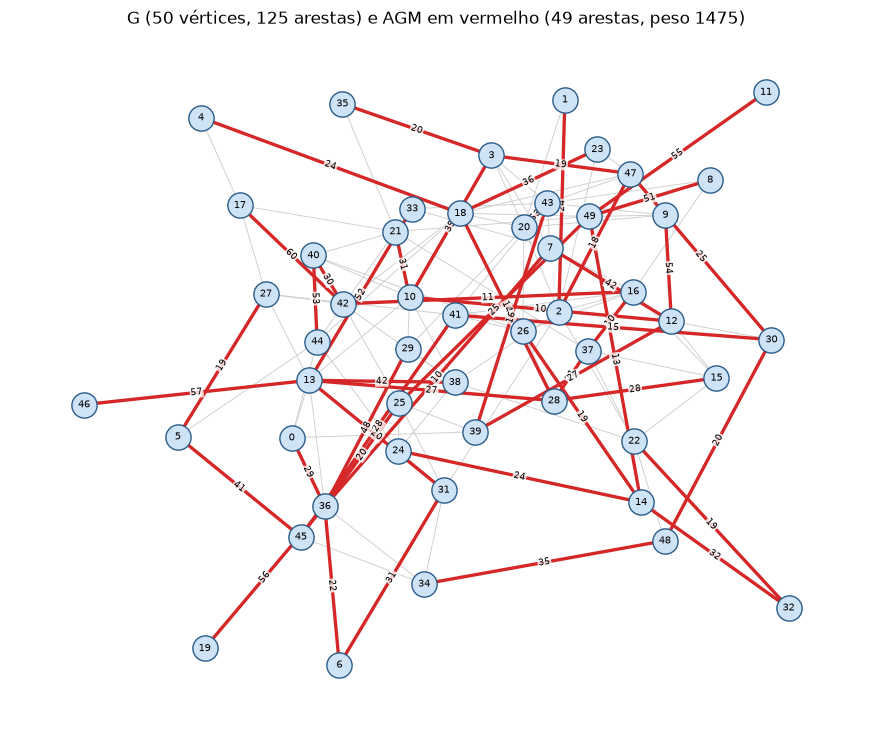

In [17]:
cj_k, cj_b, cj_p = (set(map(tuple, x)) for x in (agm_k, agm_b, agm_p))
ref = nx.minimum_spanning_tree(G4, algorithm="kruskal")
peso_nx = int(sum(d["weight"] for *_, d in ref.edges(data=True)))
print(pd.DataFrame({"Método": ["Kruskal", "Borůvka", "Prim", "networkx (referência)"],
                    "arestas": [len(cj_k), len(cj_b), len(cj_p), ref.number_of_edges()],
                    "peso total da AGM": [peso_k, peso_b, peso_p, peso_nx]}).to_string(index=False))
print("\nConjuntos de arestas idênticos (Kruskal = Borůvka = Prim):", cj_k == cj_b == cj_p)
print("Peso igual ao da referência (networkx):", peso_k == peso_b == peso_p == peso_nx)
T = nx.Graph(); T.add_weighted_edges_from(agm_k)
print("É árvore geradora (conexa, acíclica, 49 arestas, 50 vértices):",
      nx.is_tree(T) and T.number_of_nodes() == N4)
# propriedade do ciclo: nenhuma aresta fora da AGM é mais leve que o maior peso do caminho na árvore entre seus extremos
ok = all(w >= max(T[a][b]["weight"] for a, b in zip(p, p[1:]))
         for u, v, w in E4 if (u, v, w) not in cj_k
         for p in [nx.shortest_path(T, u, v)])
print("Propriedade do ciclo (toda aresta fora da AGM é a mais pesada do ciclo que forma com a AGM):", ok)

pos = nx.spring_layout(G4, seed=3, k=0.35, iterations=200)
fig, ax = plt.subplots(figsize=(11, 9))
nx.draw_networkx_edges(G4, pos, edge_color="#d0d0d0", width=0.7, ax=ax)
nx.draw_networkx_edges(G4, pos, edgelist=[(u, v) for u, v, w in agm_k], edge_color="#d62728", width=2.4, ax=ax)
nx.draw_networkx_nodes(G4, pos, node_color="#cfe3f7", edgecolors="#2b5d8a", node_size=330, ax=ax)
nx.draw_networkx_labels(G4, pos, font_size=7.5, ax=ax)
nx.draw_networkx_edge_labels(T, pos, {(u, v): w for u, v, w in agm_k}, font_size=6.5, label_pos=0.5, ax=ax,
                             bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=.8))
ax.set_title(f"G (50 vértices, 125 arestas) e AGM em vermelho (49 arestas, peso {peso_k})"); ax.axis("off")
plt.show()

### 4.E Discussão

- Os três métodos encontram a **mesma AGM** (mesmas 49 arestas e mesmo peso total), validada contra a implementação do `networkx` e pela **propriedade do ciclo**: toda aresta rejeitada é a mais pesada do ciclo que formaria com a árvore (teorema da questão 2.A). Isso concorda com a teoria: com uma ordem total de arestas a AGM é única, e a escolha de cada algoritmo é justificada pela propriedade do **corte** (arestas aceitas) e do **ciclo** (arestas rejeitadas).
- **Como cada um chega lá:** Kruskal olha o grafo **globalmente** por ordem de peso e constrói uma *floresta* que vai se fundindo; Prim **cresce uma única árvore** a partir de um vértice; Borůvka funde **todas as componentes ao mesmo tempo** em poucas rodadas, o que o torna o mais adequado à paralelização (questão 3.A).
- **Esforço observado:** Kruskal examinou 67 das 125 arestas (49 aceitas e 18 rejeitadas) e parou ao completar a árvore; Borůvka terminou em apenas 4 rodadas (50 → 11 → 4 → 2 → 1 componentes), abaixo do limite $\lceil\log_2 50\rceil=6$, e a primeira rodada sozinha já escolheu 39 das 49 arestas.
- **Desempate:** sem o critério $(w,u,v)$ comum, os algoritmos poderiam devolver AGMs *diferentes*, mas todas com o mesmo peso total, pois a AGM só é única quando os pesos são distintos.

## 5. Dentro das motivações de AGM
a. Considere que é dado um grafo valorado positivamente e conexo G(V,E), onde um subconjunto de vértices de Vs V tal que | Vs |V, construa uma árvore expandida de menor custo entre os vértices de Vs sobre G(V,E).

b. Considerando um grafo Euclidiano completo K40 no 2, gere um dendrograma da AGM sobre os vértices da AGM, usando Kruskal, Prim e Boruvka (Mostre visualmente a diferença entre as soluções e comente o seu resultado).

c. Considerando agora um grafo Euclidiano K467 no 7, correspondente às características de um conjunto de imóveis à venda, gere um Espalier da AGM deste grafo, e o compare ao dendrograma discutindo a solução obtida (buscar dados nas bibliotecas IRVINE (https://archive.ics.uci.edu/dataset/292/wholesale+customers).)

# CAMINHOS MÍNIMOS

## 6. Discuta as seguintes aplicações de caminhos mínimos em grafos:

A. Cálculo do caminho mais curto (a pé) entre um ponto origem e um destino de uma cidade;

B. Cálculo do caminho mais rápido (de carro) entre um ponto origem e um destino de uma cidade;

C. Sequenciamento de rotas de veículos;

D. Árvores de Steiner em Grafos;

E. Planejamento de tarefas de um projeto.

---

### A. Caminho mais curto a pé

**Modelagem.** Os vértices são esquinas, cruzamentos, entradas de edifícios e pontos de interesse; as ligações são trechos de calçada, faixas de pedestres, passarelas, escadas e atalhos (praças, parques). Como o pedestre anda nos dois sentidos de uma calçada, o grafo é essencialmente **não orientado** $G(V,E)$ (as vias de mão única para carros *não* valem para quem anda a pé). O peso $w(e)$ é o comprimento do trecho em metros, ou, de forma mais fiel, o tempo $w(e)=\ell(e)/v$, com $v \approx 1{,}2\text{ m/s}$.

**Particularidades.**
- Os pesos são positivos, então o problema é resolvido com **Dijkstra** ($O((n+m)\log n)$) ou, para uma consulta origem-destino, com **A\*** usando como heurística a distância em linha reta (euclidiana ou de Haversine), que é admissível e consistente, ou com Dijkstra bidirecional.
- Podem-se acrescentar penalidades: espera em semáforo, escadas, rampas íngremes, calçadas sem iluminação à noite, acessibilidade (cadeirante). Isso muda o peso, mas o problema continua sendo de caminho mínimo com pesos positivos.
- É um problema de **um par** $(s,t)$: não é necessário calcular a árvore completa, e o algoritmo pode parar assim que $t$ recebe rótulo permanente.

---

### B. Caminho mais rápido de carro

**Modelagem.** O grafo é **orientado** (ou misto): ruas de mão única são arcos, ruas de mão dupla são arestas (dois arcos). O peso é o **tempo de percurso**, $w(a)=\ell(a)/v(a)$, em que $v(a)$ é a velocidade média do trecho (limite da via, tipo de pavimento, congestionamento). O caminho *mais rápido* não coincide, em geral, com o *mais curto*: uma via expressa mais longa pode ser mais rápida que uma rua curta e lenta.

**Particularidades.**
- **Pesos dependentes do tempo** ($w_a(\tau)$): o trânsito varia ao longo do dia. Desde que a propriedade FIFO seja respeitada (sair depois nunca faz chegar antes), Dijkstra continua válido.
- **Restrições de movimento**: proibido retornar, proibido virar à esquerda, mãos únicas, balões. Elas quebram a hipótese de que o estado é só o vértice, e levam ao grafo expandido de arcos (é exatamente o que será feito na questão 10).
- **Escala**: redes viárias têm milhões de vértices. Na prática usam-se pré-processamentos (*Contraction Hierarchies*, *ALT*, *Arc Flags*, hierarquia de vias), que respondem consultas em milissegundos.
- Outros custos (pedágio, consumo de combustível) levam a variantes **multiobjetivo** ou com **restrição de recurso**, que já são mais difíceis (NP-difíceis).

---

### C. Sequenciamento de rotas de veículos

**Modelagem.** No *Problema do Caixeiro Viajante* (PCV) e no *Problema de Roteirização de Veículos* (PRV/VRP), deve-se decidir **a ordem** em que um conjunto de clientes é visitado, minimizando o custo total (e respeitando capacidade, janelas de tempo, número de veículos etc.).

**Papel do caminho mínimo.** Os clientes não estão ligados diretamente na malha viária: entre dois clientes $i$ e $j$ o veículo percorre o caminho mínimo da rede. Por isso, o primeiro passo é calcular a **matriz de distâncias mínimas** entre todos os pares de interesse (depósito e clientes), isto é, o **fecho métrico** do grafo. Essa matriz define um grafo completo $K_{|C|}$ cujo custo $c_{ij}=d(i,j)$ satisfaz a desigualdade triangular. Sobre esse grafo aplicam-se as heurísticas e métodos exatos de sequenciamento (vizinho mais próximo, economias de Clarke-Wright, 2-opt/3-opt, *branch-and-cut*, metaheurísticas). Depois, cada aresta da rota é substituída pelo caminho mínimo correspondente para obter a rota física.

**Ligação com a questão 9:** é exatamente por isso que a *matriz completa de caminhos mínimos* (Floyd-Warshall ou $n$ execuções de Dijkstra) é uma etapa de pré-processamento clássica em roteirização.

---

### D. Árvores de Steiner em grafos

**Problema.** Dado $G(V,E)$ valorado positivamente e um conjunto de **terminais** $T \subseteq V$, encontrar a subárvore de menor custo que contém todos os terminais, podendo usar vértices extras (**pontos de Steiner**) que não estão em $T$. Aplicações: redes de telecomunicações e de distribuição (água, energia, gás), projeto de circuitos VLSI, filogenia.

**Diferença para a AGM.** Se $T=V$, é a árvore geradora mínima, que se resolve em tempo polinomial. Se $T \subsetneq V$, o problema é **NP-difícil**: os vértices de Steiner podem diminuir o custo e escolher quais usar é a parte difícil.

**Uso de caminhos mínimos (heurística de Kou-Markowsky-Berman).**
1. Calcular os caminhos mínimos entre todos os pares de terminais e montar o grafo completo $G_T$ (fecho métrico sobre $T$).
2. Obter uma AGM $M$ de $G_T$.
3. Substituir cada aresta de $M$ pelo caminho mínimo correspondente em $G$.
4. Calcular a AGM do subgrafo resultante e podar folhas que não são terminais.

Essa heurística tem fator de aproximação $2(1-1/|T|)$. O método exato clássico (Dreyfus-Wagner) é $O(3^{|T|}n + 2^{|T|}n^2 + n^3)$, que é usado em instâncias com poucos terminais e também apoia-se em caminhos mínimos. O item **5.a** da lista é exatamente este problema.

---

### E. Planejamento de tarefas de um projeto (CPM/PERT)

**Modelagem.** Cada tarefa é um vértice (ou arco) de um grafo orientado **acíclico** (DAG) que representa as precedências; o peso é a duração. O **menor tempo possível** para concluir o projeto é o comprimento do **caminho mais longo** entre o início e o fim, o chamado **caminho crítico**: qualquer atraso em uma tarefa dele atrasa todo o projeto.

**Relação com caminho mínimo.** Maximizar equivale a minimizar o oposto: o caminho mais longo em $G$ é o caminho mínimo em $G$ com pesos $-d$. Isso só é permitido porque o grafo é acíclico, de modo que não existem ciclos negativos. Em um DAG o problema se resolve em $O(n+m)$ com um único passe em **ordem topológica**, que é um algoritmo de *label correcting*. Os resultados clássicos do CPM (início/término mais cedo e mais tarde, **folga**) saem das duas passadas, para frente e para trás.

**Extensões.** PERT (durações probabilísticas), restrições de recursos (RCPSP, que já é NP-difícil) e custos de aceleração (*crashing*).

## 7. Apresente o teorema fundamental do caminho mínimo e faça a sua prova.

---

Seja $G(V,A)$ um grafo orientado com função de pesos $w:A\to\mathbb{R}$ **sem ciclos de comprimento negativo** (em particular, vale para $w>0$). O peso de um caminho $P=(v_1,v_2,\dots,v_k)$ é $w(P)=\sum_{i=1}^{k-1} w(v_i,v_{i+1})$ e a distância é $d(u,v)=\min\{w(P): P \text{ caminho de } u \text{ a } v\}$.

### Teorema fundamental (subestrutura ótima / princípio da otimalidade)

> **Se $P=(v_1,v_2,\dots,v_k)$ é um caminho mínimo de $v_1$ a $v_k$, então para quaisquer $1\le i\le j\le k$ o subcaminho $P_{ij}=(v_i,v_{i+1},\dots,v_j)$ é um caminho mínimo de $v_i$ a $v_j$.**

### Prova (por contradição, "recorta e cola")

Decomponha $P$ em três partes: $P = P_{1i} \;\cup\; P_{ij} \;\cup\; P_{jk}$, de modo que
$$w(P)=w(P_{1i})+w(P_{ij})+w(P_{jk}).$$

Suponha, por absurdo, que $P_{ij}$ **não** seja um caminho mínimo de $v_i$ a $v_j$. Então existe um caminho $P'_{ij}$ de $v_i$ a $v_j$ com $w(P'_{ij})<w(P_{ij})$.

Troque $P_{ij}$ por $P'_{ij}$ em $P$. Obtemos um passeio $P'$ de $v_1$ a $v_k$:
$$w(P')=w(P_{1i})+w(P'_{ij})+w(P_{jk}) < w(P_{1i})+w(P_{ij})+w(P_{jk}) = w(P).$$

Se $P'$ tem vértices repetidos, ele contém ciclos. Como não há ciclos negativos, remover cada ciclo não aumenta o peso, e ficamos com um **caminho** $P''$ de $v_1$ a $v_k$ com $w(P'')\le w(P')<w(P)$. Isso contradiz a hipótese de que $P$ é mínimo. Logo $P_{ij}$ é um caminho mínimo. $\blacksquare$

### Corolário 1 (equações de Bellman)

Para todo $v\neq s$:
$$d(s,v)=\min_{(u,v)\in A}\{\,d(s,u)+w(u,v)\,\},\qquad d(s,s)=0.$$

*Prova.* ($\le$) Qualquer caminho mínimo de $s$ a $u$ seguido do arco $(u,v)$ é um passeio de $s$ a $v$, logo $d(s,v)\le d(s,u)+w(u,v)$ para todo $(u,v)\in A$. ($\ge$) Seja $P$ um caminho mínimo de $s$ a $v$ e $(u,v)$ seu último arco. Pelo teorema, o prefixo $P_{su}$ é mínimo, então $d(s,v)=w(P)=d(s,u)+w(u,v)$ para esse $u$. Portanto o mínimo é atingido. $\blacksquare$

### Corolário 2 (condições de otimalidade)

Um vetor de rótulos $d(\cdot)$, com $d(s)=0$, é o vetor de distâncias a partir de $s$ se, e somente se, (i) $d(v)\le d(u)+w(u,v)$ para todo arco $(u,v)$ e (ii) todo $v\ne s$ possui um arco "justo" $(u,v)$ com $d(v)=d(u)+w(u,v)$, formando um caminho justo desde $s$. A condição (i) é exatamente o que os algoritmos de *label correcting* tentam atingir (eliminam arcos violados), e a (ii) permite recuperar a **árvore de caminhos mínimos** pelo vetor de predecessores.

### Observações

- **Caminho simples:** com $w>0$ todo caminho mínimo é simples (sem vértices repetidos), então existe uma árvore de caminhos mínimos com $n-1$ arcos.
- **Condição necessária:** a hipótese de "sem ciclos negativos" é indispensável. Com um ciclo negativo alcançável, $d(s,v)=-\infty$.
- **Um contraexemplo para a versão com restrições:** o teorema vale para o *estado = vértice*. Quando há movimentos proibidos (questão 10), o custo de continuar depende do arco anterior, e a subestrutura ótima deixa de valer sobre vértices. Ela volta a valer se o estado for o **arco**.

## 8. Caracterize os tipos de algoritmo de caminho mínimo, e o relacione a um método conhecido:

A. Label Setting

B. Label Correcting

C. Caminho mínimo de $s$ a um $t \in V-\{s\}$ sobre um grafo misto $G(V,E,A)$ valorado positivamente e sem loop.

D. Caminho mínimo de todo $s$ a todo $t\in V-\{s\}$ um grafo misto $G(V,E,A)$ valorado positivamente e sem loop.

---

Todos os algoritmos desta família mantêm, para cada vértice $v$, um **rótulo** $d(v)$ (limite superior da distância) e um **predecessor** $p(v)$, e usam o mesmo passo básico de **relaxação** do arco $(u,v)$:

$$\text{se } d(u)+w(u,v)<d(v) \;\Rightarrow\; d(v)\leftarrow d(u)+w(u,v),\; p(v)\leftarrow u.$$

O que diferencia as duas grandes classes é **quando um rótulo se torna definitivo**.

### A. Label Setting (rótulo fixado)

- **Característica:** a cada iteração, o vértice não fixado de **menor rótulo** tem seu rótulo declarado **permanente**; esse rótulo não é mais alterado. O vértice é "setado" uma única vez e cada arco é relaxado uma única vez.
- **Hipótese:** pesos **não negativos** ($w\ge0$). Com pesos negativos o menor rótulo temporário deixa de ser garantidamente o ótimo, e o método falha.
- **Princípio:** é uma estratégia gulosa apoiada no teorema da questão 7; o vértice de menor rótulo não pode ser melhorado por nenhum caminho que passe por vértices ainda não fixados, pois todos têm rótulo $\ge$ ao dele e os arcos são $\ge 0$.
- **Método conhecido: Algoritmo de Dijkstra (1959).** Complexidade $O(n^2)$ com vetor, $O((n+m)\log n)$ com heap binário, $O(m+n\log n)$ com heap de Fibonacci. Também são label setting a versão de Dial (baldes) e o A\* com heurística consistente.

### B. Label Correcting (rótulo corrigido)

- **Característica:** os rótulos são **limites superiores provisórios** que podem ser corrigidos várias vezes. Nenhum rótulo é garantido definitivo antes do fim; o algoritmo termina quando **nenhum arco viola** $d(v)\le d(u)+w(u,v)$ (Corolário 2 da questão 7).
- **Esquema geral:** manter uma **lista** de candidatos (vértices cujo rótulo mudou); retirar um vértice, relaxar seus arcos de saída e inserir na lista os vértices cujo rótulo melhorou. A **disciplina da lista** define cada método.
- **Vantagens:** aceita **pesos negativos**. A detecção de ciclo negativo depende da implementação: no Bellman-Ford clássico, faz-se uma relaxação adicional após as $n-1$ passagens, e se algum rótulo ainda melhora existe ciclo negativo alcançável; em versões com lista, usam-se outros critérios (por exemplo, contar quantas vezes cada vértice entra na lista ou procurar ciclo no grafo de predecessores). É mais fácil de paralelizar e de adaptar.
- **Métodos conhecidos:**
  - **Bellman-Ford / Moore** (lista FIFO): $O(nm)$;
  - **D'Esopo-Pape** (deque: reentrantes vão para o início; pior caso exponencial, mas muito rápido na prática em redes viárias);
  - **Threshold** de Glover, Klingman e Phillips (duas listas separadas por um limiar);
  - **Extended TANYAKUMU** (propagação por número de arcos do caminho).


### C. Caminho mínimo de $s$ a um $t$ em grafo misto $G(V,E,A)$, positivo e sem loop

- **Transformação:** cada **aresta** $\{u,v\}\in E$ de peso $w$ vira **dois arcos** $(u,v)$ e $(v,u)$ com o mesmo peso $w$; os arcos de $A$ ficam como estão. Como $w>0$, não surgem ciclos negativos. Como não há loops, não há arcos $(v,v)$, e arcos paralelos ficam apenas com o de menor peso.
- **Método:** **Dijkstra com parada antecipada**: encerra-se quando $t$ é retirado da fila (ganha rótulo permanente), sem necessidade de explorar o resto do grafo. É um problema **um-para-um**.
- **Aceleração:** Dijkstra **bidirecional** (uma busca de $s$ nos arcos diretos e outra de $t$ nos arcos reversos) ou **A\*** com heurística admissível (distância euclidiana, quando existem coordenadas).
- Complexidade: $O((n+m)\log n)$ no pior caso, tipicamente muito menos.

### D. Caminho mínimo de todo $s$ a todo $t$ em grafo misto, positivo e sem loop

- **Problema:** **todos os pares** (matriz $n\times n$ de distâncias e caminhos).
- **Mesma transformação** do item C (aresta $\to$ dois arcos).
- **Métodos conhecidos:**
  - **Floyd-Warshall:** algoritmo de **programação dinâmica** para todos os pares (não é um método clássico de *label correcting*), $O(n^3)$, $O(n^2)$ de memória, simples, melhor para grafos **densos**;
  - **$n$ execuções de Dijkstra:** $O(n(n+m)\log n)$, melhor para grafos **esparsos**;
  - **Johnson**: reponderação mais $n$ Dijkstra, caso houvesse pesos negativos (aqui não é necessário porque $w>0$).

| Item | Tipo de problema | Classe | Método de referência | Complexidade |
|---|---|---|---|---|
| A | $s\to V$, $w\ge0$ | *Label setting* | Dijkstra | $O((n+m)\log n)$ |
| B | $s\to V$, $w$ qualquer sem ciclo negativo | *Label correcting* | Bellman-Ford/Moore, Pape, Threshold | $O(nm)$ |
| C | $s\to t$ em grafo misto $w>0$ | *Label setting* com parada antecipada | Dijkstra (uni/bidirecional), A\* | $O((n+m)\log n)$ |
| D | todos $\to$ todos, misto, $w>0$ | Todos os pares | Floyd-Warshall ou $n\times$Dijkstra | $O(n^3)$ ou $O(n(n+m)\log n)$ |

## 10. A partir do método de Dijkstra, considere incluir restrições de movimentos proibidos (proibido retornar, proibido dobrar à direita ou à esquerda, proibido seguir em frente). Prove que seu novo algoritmo continua calculando o caminho mais curto entre quaisquer pares de vértices $s,t$ do grafo valorado e f-conexo dado. Mostre um exemplo usando um grafo $G(V,E,A)$ valorado positivamente com 40 vértices e 120 ligações e f-conexo.

---

### 10.1 Por que o Dijkstra "puro" falha

Um **movimento** é uma tripla $(a,b,c)$: chega-se a $b$ vindo de $a$ e sai-se para $c$. Ele é classificado pela geometria dos vértices:

| Movimento | Definição |
|---|---|
| **retornar** | $c=a$ (retorno em U pelo mesmo trecho) |
| **frente** | ângulo de giro $\theta\in[-30^\circ,30^\circ]$ |
| **esquerda** | $\theta>30^\circ$ (anti-horário) |
| **direita** | $\theta<-30^\circ$ (horário) |

onde $\theta$ é o ângulo orientado entre os vetores $\overrightarrow{ab}$ e $\overrightarrow{bc}$. Seja $\Pi$ o conjunto de movimentos proibidos.

No Dijkstra clássico o **estado é o vértice**: ao fixar $d(b)$, assume-se que o melhor caminho até $b$ é o melhor ponto de partida para continuar. Com movimentos proibidos isso é falso, porque **o que se pode fazer depois de $b$ depende de por qual arco se chegou a $b$**. O caminho mais curto até $b$ pode chegar por um arco que proíbe a única saída desejada, enquanto um caminho um pouco mais longo chega por outro arco que a permite. Logo, a subestrutura ótima da questão 7 não vale sobre vértices. Além disso, a rota ótima pode **repetir vértices** (por exemplo, dar a volta no quarteirão quando retornar é proibido).

### 10.2 Algoritmo: Dijkstra sobre o grafo expandido de arcos

**Estado = arco** em que se está. Define-se o digrafo expandido $G'=(A,T)$:

- cada **arco** $i=(a,b)\in A$ de $G$ (arestas contam como dois arcos) é um **vértice** de $G'$;
- há uma transição $i\to j$, com $i=(a,b)$ e $j=(b,c)$, **se e somente se** o movimento $(a,b,c)$ **não** pertence a $\Pi$; o custo dessa transição é $w(j)=w(b,c)$;
- para a origem $s$ não há arco anterior, então todo arco $j$ que sai de $s$ é um estado inicial com $\text{dist}(j)=w(j)$ (a **fonte virtual** $s^*$ liga-se a eles com custo $w(j)$).

Executa-se **Dijkstra** a partir de $s^*$ em $G'$. A distância restrita é
$$d_\Pi(s,t)=\min_{i=(a,t)\in A}\ \text{dist}(i),\qquad s\neq t.$$
A rota é recuperada seguindo os predecessores de estados (arcos) e lendo os vértices.

### 10.3 Prova de correção

**Teorema.** Para todo par $s\neq t$ para o qual exista uma rota viável (que respeita $\Pi$), o algoritmo devolve $d_\Pi(s,t)$, o custo mínimo entre todas as rotas viáveis de $s$ a $t$, e uma rota que o realiza. Se não existir rota viável, devolve $\infty$.

*Prova.*

**(i) Bijeção entre rotas viáveis e caminhos em $G'$.** Uma rota viável de $s$ a $t$ é uma sequência de vértices $s=v_0,v_1,\dots,v_k=t$ ($k\ge1$) em que cada $(v_{r},v_{r+1})\in A$ e cada tripla consecutiva $(v_{r-1},v_r,v_{r+1})\notin\Pi$. Ela corresponde de forma única à sequência de arcos $i_1=(v_0,v_1),\dots,i_k=(v_{k-1},v_k)$, e esta é um caminho em $G'$ que começa em um arco que sai de $s$ e termina em um arco que chega a $t$: a transição $i_r\to i_{r+1}$ existe exatamente quando a tripla correspondente é permitida. A correspondência é inversa e preserva o custo, pois
$$w(\text{rota})=\sum_{r=1}^{k} w(i_r)=w(i_1)+\sum_{r=1}^{k-1}\text{custo}(i_r\to i_{r+1}),$$
que é o comprimento do caminho em $G'$ a partir de $s^*$. Logo,
$$d_\Pi(s,t)=\min_{i\in\text{in}(t)}\ d_{G'}(s^*,i).$$

**(ii) $G'$ tem pesos positivos.** Todos os custos de $G'$ são pesos de $G$, que são positivos. Pelas hipóteses do Dijkstra (pesos $\ge 0$), o algoritmo calcula corretamente $d_{G'}(s^*,i)$ para todo estado $i$ alcançável: ao extrair da fila o estado $i$ de menor rótulo, qualquer outro caminho até $i$ precisa passar por um estado ainda não fixado, cujo rótulo é $\ge \text{dist}(i)$, e os custos restantes são $\ge0$; logo $\text{dist}(i)$ é ótimo (invariante clássica do Dijkstra, e a questão 7 vale sobre $G'$, onde o estado é o arco).

**(iii) Conclusão.** Por (i) e (ii), $\min_{i\in\text{in}(t)}\text{dist}(i)$ é o custo mínimo entre todas as rotas viáveis. Se nenhum estado $i\in\text{in}(t)$ é alcançado, não há rota viável. $\blacksquare$

**Casos particulares e consistência.**
- Com $\Pi=\emptyset$, todas as transições existem, e $d_\Pi(s,t)=d(s,t)$, a distância clássica (verificado numericamente abaixo para todos os pares).
- O algoritmo funciona para qualquer combinação de proibições, pois $\Pi$ só altera **quais transições existem**.

**Sobre a f-conexidade.** O grafo ser f-conexo garante rota para todo par apenas **sem restrições**. Com $\Pi\ne\emptyset$ pode não haver rota viável (por exemplo, um vértice com um só vizinho e $\Pi\ni$ retornar: chega-se a ele, mas não se sai). O teorema acima vale para todo par em que a rota existe, e o algoritmo **detecta** os que não têm ($\infty$). O experimento abaixo quantifica isso.

**Complexidade.** $|V'|=|A|$ e $|T|\le\sum_v \deg^-(v)\,\deg^+(v)$. Com heap: $O\big((|A|+|T|)\log|A|\big)$ por origem; $O(n\cdot(|A|+|T|)\log|A|)$ para todos os pares.

In [18]:
# ---- Preparação das questões 10 e 11 (imports e funções auxiliares usadas adiante) ----
import random, math, time, heapq
from collections import deque, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
INF = float("inf")


def dijkstra(adj, s):
    """Dijkstra clássico (label setting, heap binário). adj[u] = [(v, w), ...]"""
    n = len(adj); d = [INF] * n; p = [-1] * n; d[s] = 0
    heap = [(0, s)]
    while heap:
        du, u = heapq.heappop(heap)
        if du > d[u]:
            continue
        for v, w in adj[u]:
            nd = du + w
            if nd < d[v]:
                d[v] = nd; p[v] = u
                heapq.heappush(heap, (nd, v))
    return d, p


def todos_os_pares(metodo, g):
    """Matriz completa de distâncias D (e predecessores P) repetindo o método de uma origem."""
    D, P = [], []
    for s in range(g["n"]):
        d, p = metodo(g["adj"], s)[:2]
        D.append(d); P.append(p)
    return D, P


def fortemente_conexo(adj):
    n = len(adj)
    def alcanca(g):
        vis, pilha = {0}, [0]
        while pilha:
            u = pilha.pop()
            for v in g[u]:
                if v not in vis:
                    vis.add(v); pilha.append(v)
        return len(vis) == n
    rev = [[] for _ in range(n)]
    for u in range(n):
        for v, _ in adj[u]:
            rev[v].append(u)
    return alcanca([[v for v, _ in a] for a in adj]) and alcanca(rev)


In [19]:
import random, math, heapq
from collections import defaultdict

# ----------------------------------------------------------------------------------
# Grafo "urbano" misto G(V,E,A): 40 vértices, 120 ligações, f-conexo, com coordenadas
# ----------------------------------------------------------------------------------
def gerar_grafo_urbano(n=40, m=120, seed=7, p_mao_unica=0.25, lado=300):
    rng = random.Random(seed)
    pos = [(rng.uniform(0, lado), rng.uniform(0, lado)) for _ in range(n)]
    dist = lambda a, b: math.dist(pos[a], pos[b])
    pares = sorted((dist(i, j), i, j) for i in range(n) for j in range(i + 1, n))
    pai = list(range(n))
    def find(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    ligacoes, usado = [], set()
    # 1) árvore geradora mínima euclidiana, só ARESTAS (mão dupla) -> f-conexo
    for d, i, j in pares:
        if find(i) != find(j):
            pai[find(i)] = find(j)
            ligacoes.append((i, j, max(10, round(d)), "E")); usado.add((i, j))
    # 2) completa até m com os pares mais próximos; parte vira mão única (arco)
    for d, i, j in pares:
        if len(ligacoes) >= m:
            break
        if (i, j) in usado:
            continue
        usado.add((i, j))
        w = max(10, round(d))
        if rng.random() < p_mao_unica:
            a, b = (i, j) if rng.random() < .5 else (j, i)
            ligacoes.append((a, b, w, "A"))
        else:
            ligacoes.append((i, j, w, "E"))
    arcos = []                                   # (u, v, w)
    for u, v, w, t in ligacoes:
        arcos.append((u, v, w))
        if t == "E":
            arcos.append((v, u, w))
    saida = defaultdict(list)                    # arcos que saem de cada vértice
    for k, (u, v, w) in enumerate(arcos):
        saida[u].append(k)
    return {"n": n, "pos": pos, "ligacoes": ligacoes, "arcos": arcos, "saida": saida}


g40 = gerar_grafo_urbano()
adj40 = [[] for _ in range(g40["n"])]
for u, v, w in g40["arcos"]:
    adj40[u].append((v, w))
print(f"n = {g40['n']}, ligações = {len(g40['ligacoes'])} "
      f"(arestas = {sum(t=='E' for *_,t in g40['ligacoes'])}, arcos = {sum(t=='A' for *_,t in g40['ligacoes'])}), "
      f"arcos orientados no total = {len(g40['arcos'])}")
print("f-conexo:", fortemente_conexo(adj40))

n = 40, ligações = 120 (arestas = 96, arcos = 24), arcos orientados no total = 216
f-conexo: True


In [20]:
# ----------------------------------------------------------------------------------
# Classificação do movimento (a -> b -> c) e Dijkstra com movimentos proibidos
# ----------------------------------------------------------------------------------
LIM_FRENTE = 30.0   # graus: |giro| <= 30 => "seguir em frente"

def tipo_movimento(pos, a, b, c):
    if c == a:
        return "retornar"
    v1 = (pos[b][0] - pos[a][0], pos[b][1] - pos[a][1])
    v2 = (pos[c][0] - pos[b][0], pos[c][1] - pos[b][1])
    ang = math.degrees(math.atan2(v1[0] * v2[1] - v1[1] * v2[0], v1[0] * v2[0] + v1[1] * v2[1]))
    if abs(ang) <= LIM_FRENTE:
        return "frente"
    return "esquerda" if ang > 0 else "direita"          # y para cima: ang>0 = anti-horário = esquerda


def dijkstra_restrito(g, s, proibidos=frozenset()):
    """Dijkstra sobre o grafo expandido (estado = arco). Retorna dist[arco], pred[arco]."""
    arcos, saida, pos = g["arcos"], g["saida"], g["pos"]
    dist = [INF] * len(arcos); pred = [-1] * len(arcos)
    heap = []
    for j in saida[s]:                                   # sem arco anterior: nenhuma restrição
        dist[j] = arcos[j][2]; heapq.heappush(heap, (dist[j], j))
    while heap:
        d, i = heapq.heappop(heap)
        if d > dist[i]:
            continue
        a, b, _ = arcos[i]
        for j in saida[b]:
            c = arcos[j][1]
            if proibidos and tipo_movimento(pos, a, b, c) in proibidos:
                continue
            nd = d + arcos[j][2]
            if nd < dist[j]:
                dist[j] = nd; pred[j] = i; heapq.heappush(heap, (nd, j))
    return dist, pred


def melhor_chegada(g, dist, t):
    cand = [(dist[i], i) for i, (u, v, w) in enumerate(g["arcos"]) if v == t]
    return min(cand) if cand else (INF, -1)


def rota_restrita(g, s, t, proibidos=frozenset()):
    """(custo, lista de vértices, lista de movimentos) ou (inf, None, None)."""
    dist, pred = dijkstra_restrito(g, s, proibidos)
    c, i = melhor_chegada(g, dist, t)
    if c == INF:
        return INF, None, None
    seq = []
    while i != -1:
        seq.append(i); i = pred[i]
    seq.reverse()
    verts = [g["arcos"][seq[0]][0]] + [g["arcos"][k][1] for k in seq]
    movs = [tipo_movimento(g["pos"], verts[r - 1], verts[r], verts[r + 1]) for r in range(1, len(verts) - 1)]
    return c, verts, movs


def matriz_restrita(g, proibidos=frozenset()):
    n = g["n"]
    M = [[INF] * n for _ in range(n)]
    for s in range(n):
        dist, _ = dijkstra_restrito(g, s, proibidos)
        for t in range(n):
            M[s][t] = 0 if s == t else melhor_chegada(g, dist, t)[0]
    return M


# ------------------------- verificações de correção -------------------------
n40 = g40["n"]
# (a) sem restrições == Dijkstra clássico, para todos os pares
M0 = matriz_restrita(g40)
D0, _ = todos_os_pares(dijkstra, {"n": n40, "adj": adj40})
assert M0 == D0
print("✔ (a) sem proibições, o algoritmo coincide com o Dijkstra clássico em todos os", n40 * (n40 - 1), "pares.")


# (b) validação independente: label correcting (Bellman-Ford) sobre os mesmos estados-arco
def bellman_ford_estados(g, s, proibidos):
    arcos, saida, pos = g["arcos"], g["saida"], g["pos"]
    dist = [INF] * len(arcos)
    for j in saida[s]:
        dist[j] = arcos[j][2]
    mudou = True
    while mudou:
        mudou = False
        for i, (a, b, _) in enumerate(arcos):
            if dist[i] == INF:
                continue
            for j in saida[b]:
                if tipo_movimento(pos, a, b, arcos[j][1]) in proibidos:
                    continue
                if dist[i] + arcos[j][2] < dist[j]:
                    dist[j] = dist[i] + arcos[j][2]; mudou = True
    return dist

CONJUNTOS = {
    "sem restrição": frozenset(),
    "proibido retornar": frozenset({"retornar"}),
    "proibido dobrar à direita": frozenset({"direita"}),
    "proibido dobrar à esquerda": frozenset({"esquerda"}),
    "proibido seguir em frente": frozenset({"frente"}),
    "retornar + direita": frozenset({"retornar", "direita"}),
    "retornar + esquerda": frozenset({"retornar", "esquerda"}),
    "retornar + frente": frozenset({"retornar", "frente"}),
}
for nome, pr in CONJUNTOS.items():
    for s in range(0, n40, 3):
        d1, _ = dijkstra_restrito(g40, s, pr)
        d2 = bellman_ford_estados(g40, s, pr)
        assert d1 == d2, (nome, s)
print("✔ (b) Dijkstra restrito == Bellman-Ford sobre estados-arco (validação independente) para todos os conjuntos de proibições.")


# (c) toda rota devolvida é viável e seu custo bate com o reportado
def custo_rota(g, verts):
    return sum(min(w for (u, v, w) in g["arcos"] if u == a and v == b) for a, b in zip(verts, verts[1:]))

for nome, pr in CONJUNTOS.items():
    for s, t in [(0, 17), (5, 33), (12, 38), (21, 2)]:
        c, verts, movs = rota_restrita(g40, s, t, pr)
        if verts is not None:
            assert custo_rota(g40, verts) == c and not (set(movs) & pr)
print("✔ (c) rotas devolvidas são viáveis (nenhum movimento proibido) e têm o custo reportado.")

✔ (a) sem proibições, o algoritmo coincide com o Dijkstra clássico em todos os 1560 pares.
✔ (b) Dijkstra restrito == Bellman-Ford sobre estados-arco (validação independente) para todos os conjuntos de proibições.
✔ (c) rotas devolvidas são viáveis (nenhum movimento proibido) e têm o custo reportado.


### 10.4 Exemplo no grafo de 40 vértices e 120 ligações

Avaliamos oito conjuntos de proibições sobre **todos os pares** $(s,t)$. Para cada conjunto: fração de pares com rota viável, custo médio e acréscimo médio sobre o custo sem restrições (nos pares viáveis), e quantas rotas ótimas **repetem vértices** (impossível no Dijkstra puro).

In [21]:
linhas = []
for nome, pr in CONJUNTOS.items():
    M = matriz_restrita(g40, pr)
    pares = [(s, t) for s in range(n40) for t in range(n40) if s != t]
    viaveis = [(s, t) for s, t in pares if M[s][t] < INF]
    acres = [M[s][t] - D0[s][t] for s, t in viaveis]
    # rotas com vértice repetido
    rep = 0
    for s in range(0, n40, 4):                      # amostra de origens (10) p/ economizar tempo
        dist, pred = dijkstra_restrito(g40, s, pr)
        for t in range(n40):
            if t == s: continue
            c, i = melhor_chegada(g40, dist, t)
            if c == INF: continue
            seq = []
            while i != -1: seq.append(i); i = pred[i]
            vs = [g40["arcos"][seq[-1]][0]] + [g40["arcos"][k][1] for k in reversed(seq)]
            rep += len(set(vs)) < len(vs)
    linhas.append({"Restrições (Π)": nome,
                   "pares viáveis (%)": round(100 * len(viaveis) / len(pares), 1),
                   "custo médio": round(sum(M[s][t] for s, t in viaveis) / len(viaveis), 1),
                   "acréscimo médio vs. sem restrição": round(sum(acres) / len(acres), 1),
                   "pares com custo maior (%)": round(100 * sum(a > 0 for a in acres) / len(acres), 1),
                   "rotas com vértice repetido (amostra)": rep})
display(pd.DataFrame(linhas).style.hide(axis="index"))

Restrições (Π),pares viáveis (%),custo médio,acréscimo médio vs. sem restrição,pares com custo maior (%),rotas com vértice repetido (amostra)
sem restrição,100.000000,182.100000,0.000000,0.000000,0
proibido retornar,100.000000,182.100000,0.000000,0.000000,0
proibido dobrar à direita,97.600000,204.600000,24.600000,46.800000,123
proibido dobrar à esquerda,97.600000,207.400000,27.600000,46.800000,107
proibido seguir em frente,100.000000,221.800000,39.700000,68.500000,0
retornar + direita,97.600000,218.200000,38.300000,46.800000,37
retornar + esquerda,95.300000,216.400000,38.000000,45.500000,39
retornar + frente,100.000000,221.800000,39.700000,68.500000,0


Par escolhido: s = 2, t = 12
sem restrição                            custo=  146  rota=[2, 20, 0, 12]
                                         movimentos=['frente', 'direita']
proibido retornar + dobrar à direita     custo=  402  rota=[2, 32, 31, 34, 19, 27, 4, 7, 12]
                                         movimentos=['frente', 'esquerda', 'esquerda', 'frente', 'frente', 'esquerda', 'frente']
proibido seguir em frente                custo=  456  rota=[2, 9, 32, 31, 34, 26, 38, 22, 14, 4, 17, 12]
                                         movimentos=['esquerda', 'direita', 'esquerda', 'direita', 'esquerda', 'direita', 'direita', 'esquerda', 'esquerda', 'esquerda']


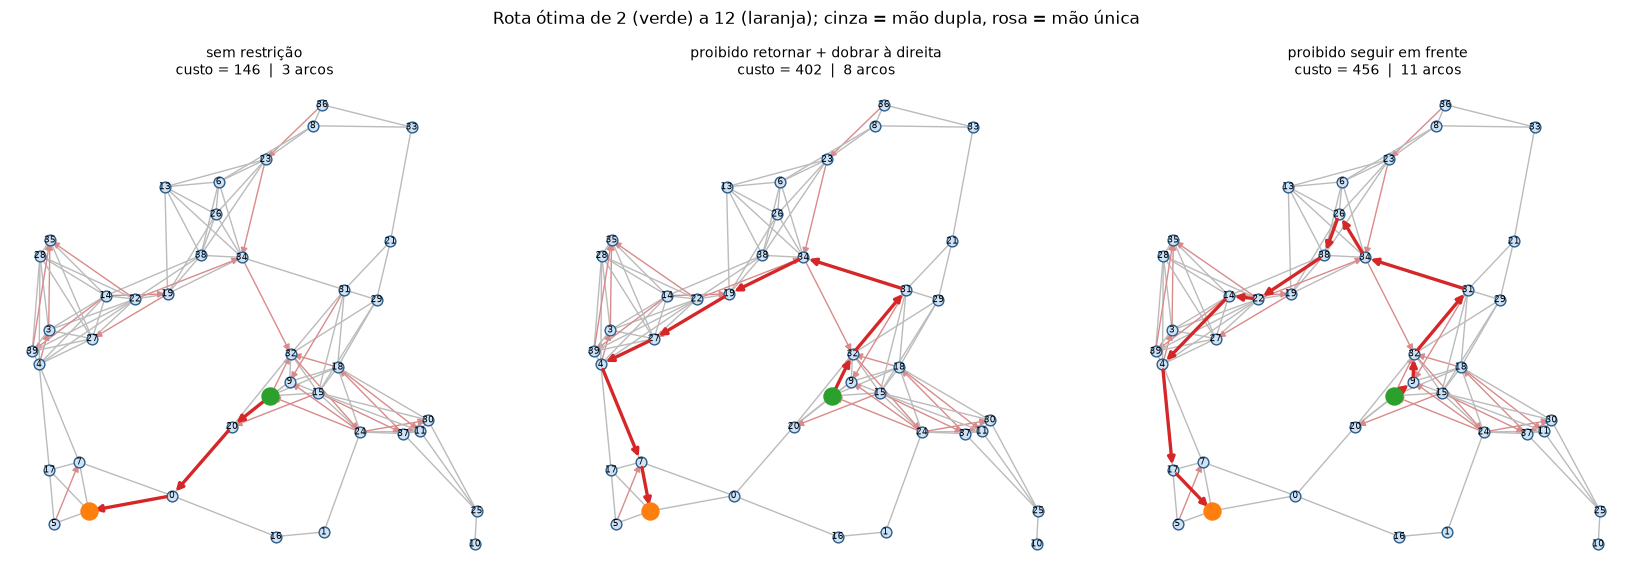

In [22]:
# ----- escolhe um par (s,t) viável nos três cenários em que AMBAS as restrições encarecem a rota, e desenha -----
CEN = [("sem restrição", frozenset()),
       ("proibido retornar + dobrar à direita", frozenset({"retornar", "direita"})),
       ("proibido seguir em frente", frozenset({"frente"}))]
Ms = [matriz_restrita(g40, pr) for _, pr in CEN]
melhor, par = (-1, -1), None
for s in range(n40):
    for t in range(n40):
        if s != t and all(M[s][t] < INF for M in Ms):
            incs = [M[s][t] - Ms[0][s][t] for M in Ms[1:]]
            score = (min(incs), sum(incs))          # os dois cenários restritos precisam mudar a rota
            if score > melhor:
                melhor, par = score, (s, t)
s, t = par
print(f"Par escolhido: s = {s}, t = {t}")

def desenhar(ax, g, verts, titulo):
    pos = g["pos"]
    for u, v, w, tp in g["ligacoes"]:
        if tp == "E":
            ax.plot(*zip(pos[u], pos[v]), color="#bbb", lw=1, zorder=1)
        else:
            ax.annotate("", xy=pos[v], xytext=pos[u], arrowprops=dict(arrowstyle="-|>", color="#d98b8b", lw=1), zorder=1)
    ax.scatter(*zip(*pos), s=60, color="#cfe3f7", edgecolors="#2b5d8a", zorder=2)
    for i, (x, y) in enumerate(pos):
        ax.text(x, y, str(i), fontsize=6.5, ha="center", va="center", zorder=3)
    if verts:
        for a, b in zip(verts, verts[1:]):
            ax.annotate("", xy=pos[b], xytext=pos[a], arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=2.4, shrinkA=4, shrinkB=4), zorder=4)
        ax.scatter(*pos[verts[0]], s=150, color="#2ca02c", zorder=5); ax.scatter(*pos[verts[-1]], s=150, color="#ff7f0e", zorder=5)
    ax.set_title(titulo, fontsize=10); ax.set_aspect("equal"); ax.axis("off")

fig, axs = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (nome, pr) in zip(axs, CEN):
    c, verts, movs = rota_restrita(g40, s, t, pr)
    desenhar(ax, g40, verts, f"{nome}\ncusto = {c}  |  {len(verts)-1} arcos")
    print(f"{nome:40s} custo={c:5d}  rota={verts}")
    print(f"{'':40s} movimentos={movs}")
plt.suptitle(f"Rota ótima de {s} (verde) a {t} (laranja); cinza = mão dupla, rosa = mão única", y=1.02)
plt.tight_layout(); plt.show()

### 10.5 Discussão do experimento

- **Proibir apenas "retornar" não altera nenhum custo** (acréscimo 0, 100% dos pares viáveis). Com pesos positivos, um caminho mínimo nunca contém o retorno $a\to b\to a$, que seria um ciclo de peso positivo. O retorno só passa a ser usado quando é a *única* saída permitida (beco sem saída, ou outras proibições ativas). O mesmo vale para "retornar + frente", que coincide com "frente" nos resultados.
- **Proibir "dobrar à direita" (ou à esquerda)** encarece cerca de 47% dos pares e deixa 97,6% dos pares com rota viável: os 2,4% restantes são pares cuja única forma de chegar exigia o movimento proibido (por exemplo, o último trecho antes do destino). **Proibir "seguir em frente"** é o que mais encarece (68,5% dos pares, acréscimo médio de 39,7), pois as rotas ficam em zigue-zague, com viradas alternadas, como se vê na figura, mas manteve 100% dos pares viáveis.
- **As rotas ótimas repetem vértices.** Com "dobrar à direita" proibido, 123 das 390 rotas da amostra (10 origens $\times$ 39 destinos) passam duas vezes por algum vértice, e com "retornar + direita" são 37. Isso sugere que, quando o retorno em U é permitido, ele substitui a conversão proibida (retorna-se e segue-se por outro caminho), e quando ele também é proibido a alternativa é dar a volta pelo quarteirão (três conversões à esquerda). O Dijkstra clássico sobre vértices **não consegue** produzir essas rotas, o que confirma a necessidade de usar o arco como estado (10.1).
- **Validação:** (a) sem proibições, o resultado coincide com o Dijkstra clássico nos 1560 pares; (b) para todos os conjuntos de proibições testados, o Dijkstra restrito coincide com um algoritmo *label correcting* independente (Bellman-Ford) sobre os mesmos estados; (c) toda rota devolvida respeita as proibições e seu custo bate com o reportado. Isso corrobora, numericamente, o teorema de 10.3.
- O par de exemplo da figura foi escolhido de propósito como **caso de maior impacto** (aquele em que as duas restrições mais encarecem a rota), para evidenciar o efeito. O acréscimo médio, mais realista, está na tabela.

---

**Modelagem.** Cada tarefa $i$ é um **intervalo** $[ES_i,\,EF_i)$ na linha do tempo, com $EF_i=ES_i+d_i$. As **precedências** dadas a priori formam um grafo orientado acíclico $G(V,A)$: o arco $(i,j)\in A$ significa que $j$ só pode começar quando $i$ terminar. Acrescentam-se duas tarefas fictícias de duração zero, **INÍCIO** (a mais à esquerda) e **FIM** (a mais à direita).

**Observação.** O gerador de grafos do AC01 não está disponível neste caderno, então as precedências são fornecidas explicitamente (um projeto de software realista com 14 tarefas), que é o "dado a priori" pedido no enunciado.

**O "menor-maior tempo".** O menor tempo possível para concluir todas as tarefas é o comprimento do **caminho mais longo** (*maior caminho*) de INÍCIO a FIM, o **caminho crítico** (CPM). O cálculo é feito em ordem topológica (um DAG é um caso de *label correcting* em que cada vértice é rotulado uma única vez):

- passada para frente: $ES_j=\max_{(i,j)\in A} EF_i$, $\;EF_j=ES_j+d_j$;
- passada para trás: $LF_i=\min_{(i,j)\in A} LS_j$, $\;LS_i=LF_i-d_i$;
- **folga** $=LS_i-ES_i$; tarefa **crítica** se folga $=0$. Complexidade $O(n+m)$.

In [23]:
# Projeto: desenvolvimento de um novo software  (id: (nome, duração em dias, predecessoras))
TAREFAS = {
    "A": ("Levantamento de requisitos",     5, []),
    "B": ("Modelagem / casos de uso",       4, ["A"]),
    "C": ("Arquitetura do sistema",         3, ["B"]),
    "D": ("Projeto do banco de dados",      4, ["B"]),
    "E": ("Protótipo de interface (UX)",    5, ["B"]),
    "F": ("Desenvolvimento do back-end",   10, ["C", "D"]),
    "G": ("Desenvolvimento do front-end",   8, ["C", "E"]),
    "H": ("Integração front-back",          4, ["F", "G"]),
    "I": ("Testes unitários",               3, ["F"]),
    "J": ("Testes de integração",           4, ["H", "I"]),
    "K": ("Documentação técnica",           6, ["C"]),
    "L": ("Homologação (aceitação)",        4, ["J", "K"]),
    "M": ("Treinamento dos usuários",       3, ["J"]),
    "N": ("Implantação (deploy)",           2, ["L", "M"]),
}

# grafo G(V,A) com INÍCIO e FIM fictícios (duração 0)
dur = {k: v[1] for k, v in TAREFAS.items()}; dur["INÍCIO"] = 0; dur["FIM"] = 0
A = [(p, k) for k, (_, _, ps) in TAREFAS.items() for p in ps]
sem_pred = [k for k, (_, _, ps) in TAREFAS.items() if not ps]
sem_suc = [k for k in TAREFAS if all(k != p for p, _ in A)]
A += [("INÍCIO", k) for k in sem_pred] + [(k, "FIM") for k in sem_suc]
V = ["INÍCIO"] + list(TAREFAS) + ["FIM"]
print(f"|V| = {len(V)}, |A| = {len(A)}")

# ordem topológica (Kahn)
grau = {v: 0 for v in V}; suc = {v: [] for v in V}; pre = {v: [] for v in V}
for u, v in A:
    grau[v] += 1; suc[u].append(v); pre[v].append(u)
fila = deque([v for v in V if grau[v] == 0]); topo = []
while fila:
    u = fila.popleft(); topo.append(u)
    for v in suc[u]:
        grau[v] -= 1
        if grau[v] == 0: fila.append(v)
assert len(topo) == len(V), "o grafo de precedências tem ciclo!"

# passada para frente (maior caminho) com predecessor crítico
ES, EF, pred_crit = {}, {}, {}
for v in topo:
    if pre[v]:
        u = max(pre[v], key=lambda x: EF[x]); ES[v] = EF[u]; pred_crit[v] = u
    else:
        ES[v] = 0
    EF[v] = ES[v] + dur[v]
T_proj = EF["FIM"]
# passada para trás
LF, LS = {}, {}
for v in reversed(topo):
    LF[v] = min((LS[w] for w in suc[v]), default=T_proj)
    LS[v] = LF[v] - dur[v]

# caminho crítico
cam = ["FIM"]
while cam[-1] in pred_crit: cam.append(pred_crit[cam[-1]])
cam = cam[::-1]
crit = {v for v in V if LS[v] - ES[v] == 0}

tabela = pd.DataFrame([{"Tarefa": v, "Descrição": TAREFAS[v][0] if v in TAREFAS else "(fictícia)",
                        "Dur.": dur[v], "Predecessoras": ",".join(p for p in pre[v]) or "-",
                        "ES": ES[v], "EF": EF[v], "LS": LS[v], "LF": LF[v],
                        "Folga": LS[v] - ES[v], "Crítica": "●" if v in crit else ""} for v in topo])
display(tabela.style.hide(axis="index").apply(lambda r: ["background-color:#fde0dd" if r["Crítica"] else "" for _ in r], axis=1))
print(f"\nMENOR TEMPO TOTAL DO PROJETO (maior caminho) = {T_proj} dias")
print("CAMINHO CRÍTICO:", " → ".join(cam))
print("Soma das durações no caminho crítico:", sum(dur[v] for v in cam), "dias")

# conferência independente: enumeração de TODOS os caminhos INÍCIO→FIM
def todos_caminhos(u, atual, saida):
    if u == "FIM": saida.append(list(atual)); return
    for v in suc[u]:
        atual.append(v); todos_caminhos(v, atual, saida); atual.pop()
caminhos = []; todos_caminhos("INÍCIO", ["INÍCIO"], caminhos)
comp = sorted(((sum(dur[v] for v in c), c) for c in caminhos), reverse=True)
assert comp[0][0] == T_proj and comp[0][1] == cam
print(f"✔ Conferência: dos {len(caminhos)} caminhos INÍCIO→FIM, o maior tem comprimento {comp[0][0]} e é o caminho crítico acima.")
print("  2º maior caminho:", comp[1][0], "dias ->", " → ".join(comp[1][1]))

|V| = 16, |A| = 21


Tarefa,Descrição,Dur.,Predecessoras,ES,EF,LS,LF,Folga,Crítica
INÍCIO,(fictícia),0,-,0,0,0,0,0,●
A,Levantamento de requisitos,5,INÍCIO,0,5,0,5,0,●
B,Modelagem / casos de uso,4,A,5,9,5,9,0,●
C,Arquitetura do sistema,3,B,9,12,10,13,1,
D,Projeto do banco de dados,4,B,9,13,9,13,0,●
E,Protótipo de interface (UX),5,B,9,14,10,15,1,
K,Documentação técnica,6,C,12,18,25,31,13,
F,Desenvolvimento do back-end,10,"C,D",13,23,13,23,0,●
G,Desenvolvimento do front-end,8,"C,E",14,22,15,23,1,
I,Testes unitários,3,F,23,26,24,27,1,



MENOR TEMPO TOTAL DO PROJETO (maior caminho) = 37 dias
CAMINHO CRÍTICO: INÍCIO → A → B → D → F → H → J → L → N → FIM
Soma das durações no caminho crítico: 37 dias
✔ Conferência: dos 13 caminhos INÍCIO→FIM, o maior tem comprimento 37 e é o caminho crítico acima.
  2º maior caminho: 36 dias -> INÍCIO → A → B → E → G → H → J → L → N → FIM


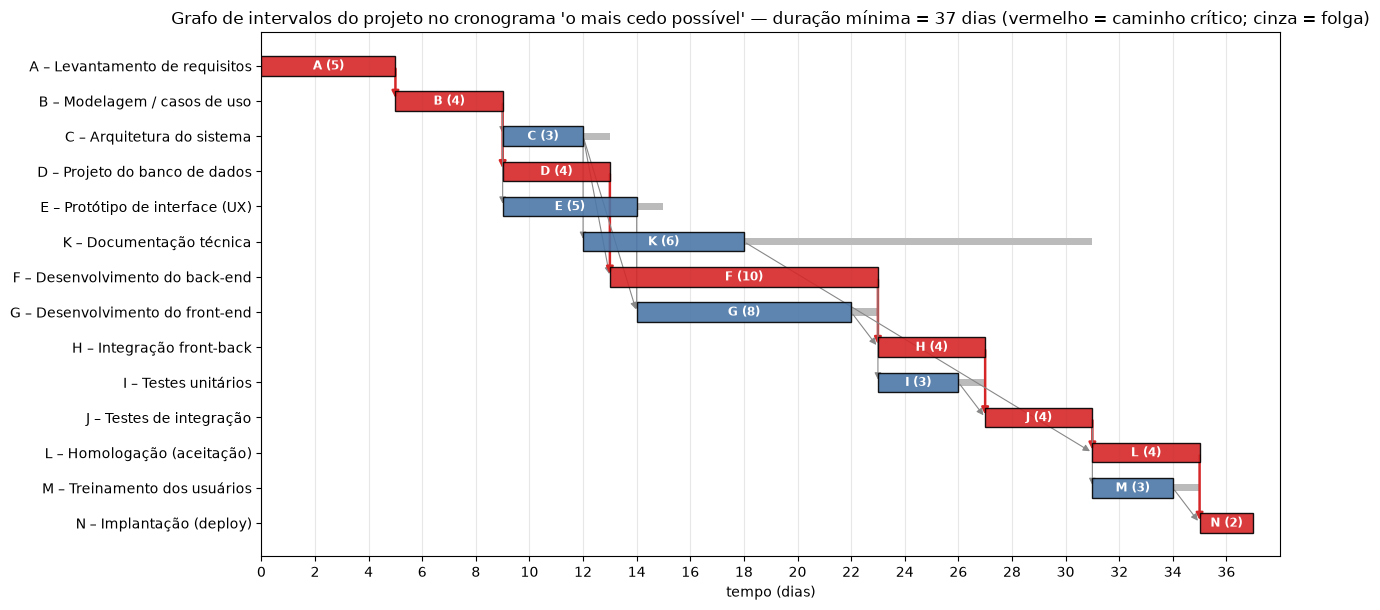

Grafo de sobreposição (intervalo): 14 vértices, 11 arestas
Maior clique = 3 tarefas simultâneas: ['F', 'G', 'K']  -> equipes/recursos paralelos necessários no pico
Grafo cordal (propriedade dos grafos de intervalo): True


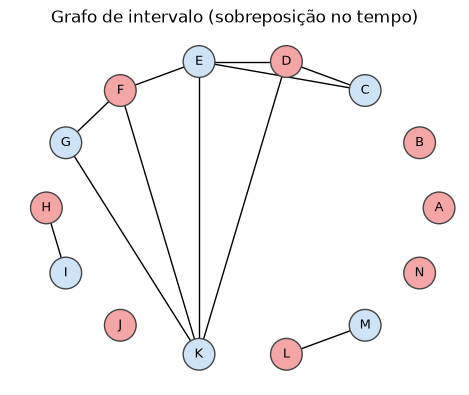

In [24]:
# ---- Diagrama de intervalos (linha do tempo) + precedências; caminho crítico em vermelho ----
reais = [v for v in V if v in TAREFAS]
fig, ax = plt.subplots(figsize=(13, 6.2))
ypos = {v: i for i, v in enumerate(reversed(sorted(reais, key=lambda v: (ES[v], v))))}
for v in reais:
    cor = "#d62728" if v in crit else "#4c78a8"
    ax.barh(ypos[v], dur[v], left=ES[v], height=0.55, color=cor, edgecolor="k", alpha=.9, zorder=3)
    ax.text(ES[v] + dur[v] / 2, ypos[v], f"{v} ({dur[v]})", ha="center", va="center", color="w", fontsize=8.5, fontweight="bold", zorder=4)
    if LS[v] - ES[v] > 0:                          # folga (janela até LF)
        ax.barh(ypos[v], LF[v] - EF[v], left=EF[v], height=0.2, color="#bbb", zorder=2)
for u, v in A:
    if u in TAREFAS and v in TAREFAS:
        cr = (u in crit and v in crit and EF[u] == ES[v])
        ax.annotate("", xy=(ES[v], ypos[v]), xytext=(EF[u], ypos[u]),
                    arrowprops=dict(arrowstyle="-|>", color="#d62728" if cr else "#888", lw=1.8 if cr else .8,
                                    connectionstyle="arc3,rad=0"), zorder=2)
ax.set_yticks(list(ypos.values())); ax.set_yticklabels([f"{v} – {TAREFAS[v][0]}" for v in ypos])
ax.set_xlabel("tempo (dias)"); ax.set_xlim(0, T_proj + 1); ax.set_xticks(range(0, T_proj + 1, 2)); ax.grid(axis="x", alpha=.3)
ax.set_title(f"Grafo de intervalos do projeto no cronograma 'o mais cedo possível' — duração mínima = {T_proj} dias "
             "(vermelho = caminho crítico; cinza = folga)")
plt.tight_layout(); plt.show()

# ---- Grafo de intervalo no sentido clássico: vértices = tarefas, aresta se os intervalos se sobrepõem ----
H = nx.Graph(); H.add_nodes_from(reais)
for i in reais:
    for j in reais:
        if i < j and ES[i] < EF[j] and ES[j] < EF[i]:
            H.add_edge(i, j)
cliques = list(nx.find_cliques(H)); maxc = max(cliques, key=len)
print(f"Grafo de sobreposição (intervalo): {H.number_of_nodes()} vértices, {H.number_of_edges()} arestas")
print(f"Maior clique = {len(maxc)} tarefas simultâneas: {sorted(maxc)}  -> equipes/recursos paralelos necessários no pico")
print("Grafo cordal (propriedade dos grafos de intervalo):", nx.is_chordal(H))
fig, ax = plt.subplots(figsize=(5.8, 4.6))
p = nx.circular_layout(H)
nx.draw(H, p, with_labels=True, node_color=["#f4a6a6" if v in crit else "#cfe3f7" for v in H], edgecolors="#444", node_size=520, font_size=9, ax=ax)
ax.set_title("Grafo de intervalo (sobreposição no tempo)"); plt.show()